# Length of stay: Decision tree

A single CART tree. With default settings it grows until its leaves are pure, so expect heavy overfitting (compare train vs. val accuracy). `max_depth` and `min_samples_leaf` are the first things to tune.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=utils.SEED)
model

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


== Decision tree ==  macro-F1 0.321  accuracy 0.416
              precision    recall  f1-score   support

     <1 week       0.52      0.55      0.53      4554
   1-4 weeks       0.38      0.38      0.38      3420
  1-3 months       0.31      0.26      0.28      2017
   3+ months       0.09      0.09      0.09       553

    accuracy                           0.42     10544
   macro avg       0.32      0.32      0.32     10544
weighted avg       0.41      0.42      0.41     10544

quadratic weighted kappa: 0.172


train accuracy 0.994  |  fit 3.1s  predict 0.0s


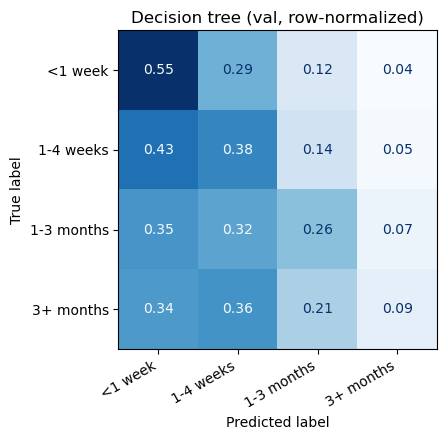

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Decision tree",
                                           results_dir=RESULTS_DIR)

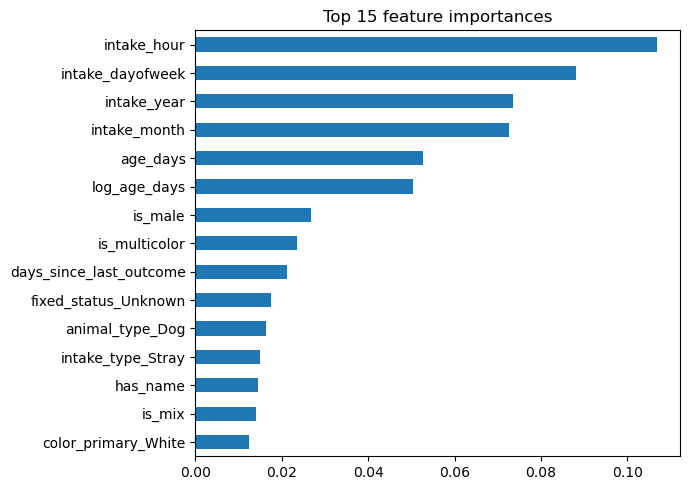

In [4]:
# Impurity-based importances (biased toward high-cardinality / continuous features;
# associations, not causes). Permutation importance is a better check after tuning.
names = pipe.named_steps["pre"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).nlargest(15)
imp.sort_values().plot(kind="barh", figsize=(7, 5), title="Top 15 feature importances")
plt.tight_layout(); plt.show()

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: depth, minimum leaf size, split criterion and class weighting. The untuned tree had 99% train accuracy (pure memorization), so limiting depth and leaf size should help the most.

In [5]:


base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'max_depth': [4, 6, 8, 10, 12, 15, 20, None],
    'min_samples_leaf': [1, 5, 20, 50, 100, 200],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Decision tree (tuned)", n_iter=25, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Decision tree (tuned): 25 candidates in 0.2 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.352
best params: {'min_samples_leaf': 100, 'max_depth': 6, 'criterion': 'entropy', 'class_weight': 'balanced'}


,min_samples_leaf,max_depth,criterion,class_weight,inner_val_f1_macro,mean_fit_time
0,100,6,entropy,balanced,0.352473,1.854145
1,50,6,entropy,balanced,0.350991,2.469128
2,1,15,gini,None,0.348472,3.123116
3,100,12,entropy,None,0.347192,3.189324
4,50,None,gini,None,0.346543,3.641789
5,100,8,gini,None,0.344771,2.890300
6,1,10,gini,None,0.341635,3.170157
7,50,10,entropy,None,0.341095,2.751952
8,5,10,entropy,None,0.340060,2.065901
9,1,10,entropy,None,0.337417,2.773442


== Decision tree (tuned) ==  macro-F1 0.374  accuracy 0.423
              precision    recall  f1-score   support

     <1 week       0.64      0.30      0.41      4554
   1-4 weeks       0.40      0.63      0.49      3420
  1-3 months       0.39      0.38      0.39      2017
   3+ months       0.16      0.31      0.21       553

    accuracy                           0.42     10544
   macro avg       0.40      0.41      0.37     10544
weighted avg       0.49      0.42      0.42     10544

quadratic weighted kappa: 0.245


train accuracy 0.443  |  fit 1.5s  predict 0.0s


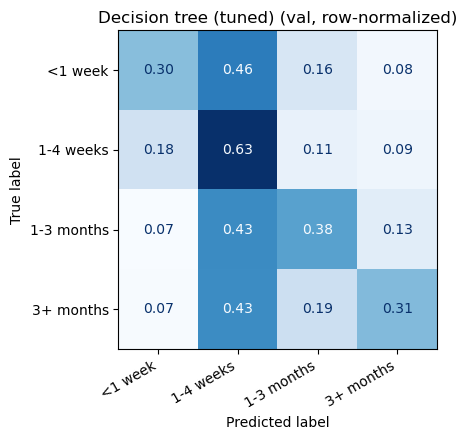

In [6]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Decision tree (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [7]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Decision tree,0.416,0.321,0.172,0.994,0.550,0.383,0.256,0.089
Decision tree (tuned),0.423,0.374,0.245,0.443,0.304,0.625,0.378,0.315
